# 02 — Components & parameters

`esc_etc` is compositional: a `Simulation` is a `Telescope` + `Sensor` + `Scene` + `Coronagraph`. This notebook builds each piece, inspects it, assembles a `Simulation` by hand, and varies parameters with `update()`.

> **Requirements:** this tutorial needs the `config_um` and `config_stp_esc` config repos and an editable install (`pip install -e .`). It uses the **UM 3 m** configuration (the supported path).

In [1]:
import astropy.units as u
from esc_etc import (Telescope, Sensor, get_scene, Coronagraph, Simulation,
                     use_lazuli_style, plot_bandpass, plot_spectra)
use_lazuli_style()

## 1. Telescope — aperture geometry

Collecting area is the Lyot-stop area (smaller than the geometric primary).

In [2]:
t = Telescope.from_default()
print('diameter_primary :', t.diameter_primary)
print('collecting area  :', t.surface)
print('f-number         :', t.f_num)
print('resolution elem  :', t.resel)

diameter_primary : 2.43 m
collecting area  : 3.6811372856047075 m2
f-number         : 36.70879621305138
resolution elem  : 0.002267435910846167 arcsec2


## 2. Sensor — detector + optical bandpass

The `Sensor` carries the detector noise properties and the full non-coronagraph throughput (`bandpass`). The PSF footprint is pinned to 225 pixels by the config.

In [3]:
s = Sensor.from_default(t)
print('gain         :', s.gain)
print('read_noise   :', s.read_noise)
print('dark_current :', s.dark_current)
print('num_psf_pix  :', s.num_psf_pixels)

assert s.num_psf_pixels.value == 225
print('sanity OK: num_psf_pixels == 225')

gain         : 0.261200000004368 electron / ct
read_noise   : 1.5221445224109558 electron(1/2) / pix(1/2)
dark_current : 0.0030703367499985944 electron / (pix s)
num_psf_pix  : 225.0 pix
sanity OK: num_psf_pixels == 225


## 3. Scene & Coronagraph

The `Scene` holds the `star`, `planet`, `zodi`, and `exozodi` elements; the `Coronagraph` carries the contrast, post-processing gain, and separation.

In [4]:
scene = get_scene(t, hoststarmag=-0.353, planetdeltamag=20, bg_flux=22.5, exobg_flux=21)
c = Coronagraph.from_default(t, raw_dh_contrast=1e-8, ppgain=10, separation=0.4)
print('star mag     :', scene.star.mag)
print('planet dmag  :', scene.planet.deltamag)
print('contrast     :', c.raw_dh_contrast, '| ppgain:', c.ppgain, '| sep:', c.separation)

star mag     : -0.353
planet dmag  : 20
contrast     : 1e-08 | ppgain: 10 | sep: 0.4


## 4. Assemble a Simulation by hand

`from_components` wires the four pieces together (equivalent to `from_default`).

In [5]:
sim = Simulation.from_components(t, s, scene, c)
print('SNR:', round(sim.get_snr(total_time=3600 * u.s, frame_time=100 * u.s)['snr'], 4))

SNR: 8.9221


## 5. Vary parameters with `update()` / `reset()`

`update()` mutates a component in place (with `child__param=` routing); the next `get_snr` reflects the change. `reset()` restores a component's initial values.

In [6]:
base = sim.get_snr(total_time=3600 * u.s, frame_time=100 * u.s)['snr']
scene.update(star__mag=2.0)   # fainter host star
c.update(ppgain=100)          # stronger post-processing
changed = sim.get_snr(total_time=3600 * u.s, frame_time=100 * u.s)['snr']
print('baseline SNR:', round(base, 3), '-> after update:', round(changed, 3))

scene.star.reset(); c.reset()  # restore each component
restored = sim.get_snr(total_time=3600 * u.s, frame_time=100 * u.s)['snr']
print('after reset :', round(restored, 3))
assert abs(restored - base) < 1e-6

baseline SNR: 8.922 -> after update: 2.544
after reset : 8.922


## 6. Inspect the bandpass and the scene spectra

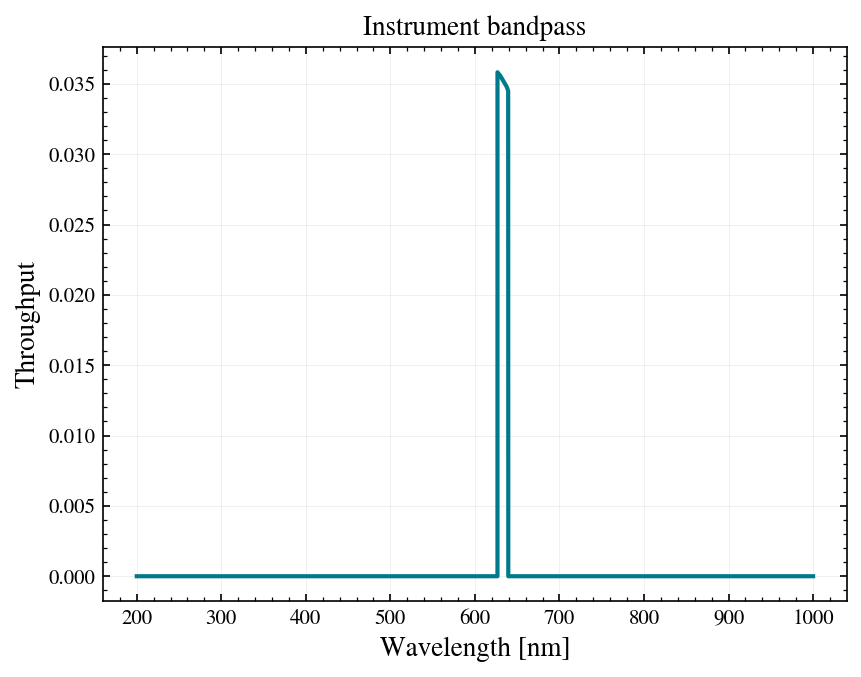

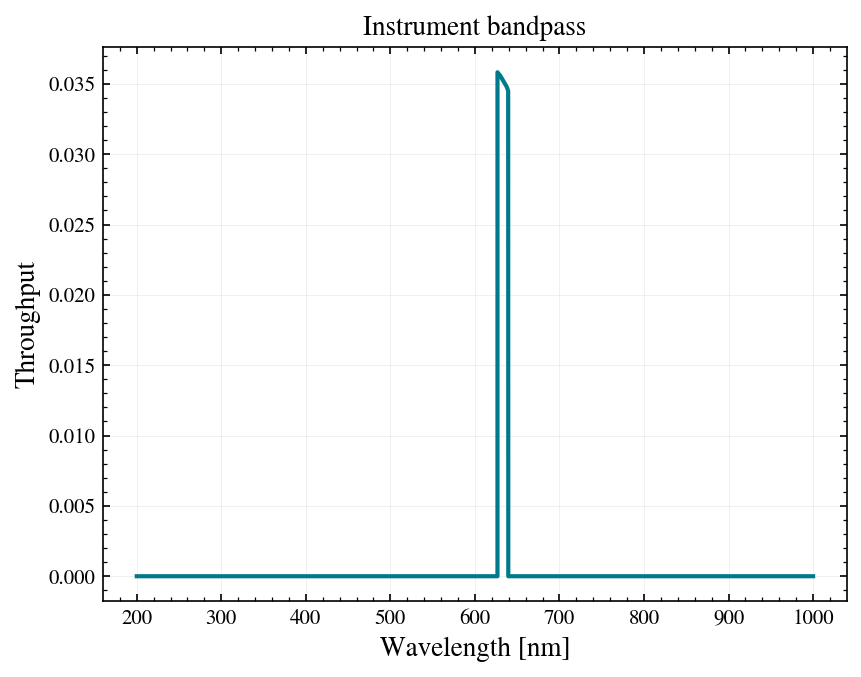

In [7]:
fig, ax = plot_bandpass(sim)
ax.set_title('Instrument bandpass')
fig

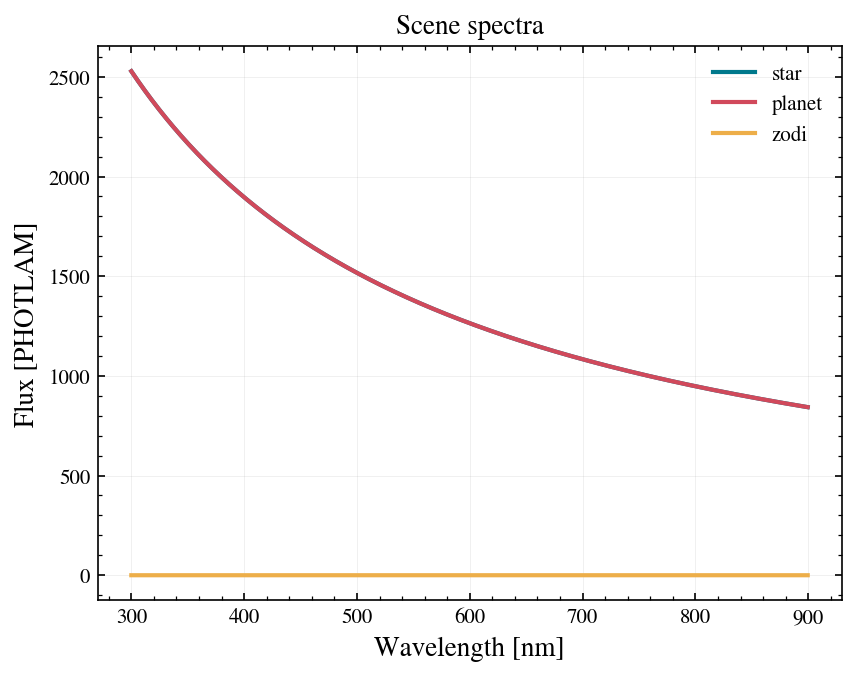

In [8]:
fig, ax = plot_spectra(sim.scene)
ax.set_title('Scene spectra')
fig

## What you learned

- Build `Telescope`/`Sensor`/`Scene`/`Coronagraph` independently and inspect them.
- `Simulation.from_components(...)` assembles them.
- `update()` varies parameters in place; `reset()` restores a component.

**Next:** notebook 03 dives into the coronagraph knobs.